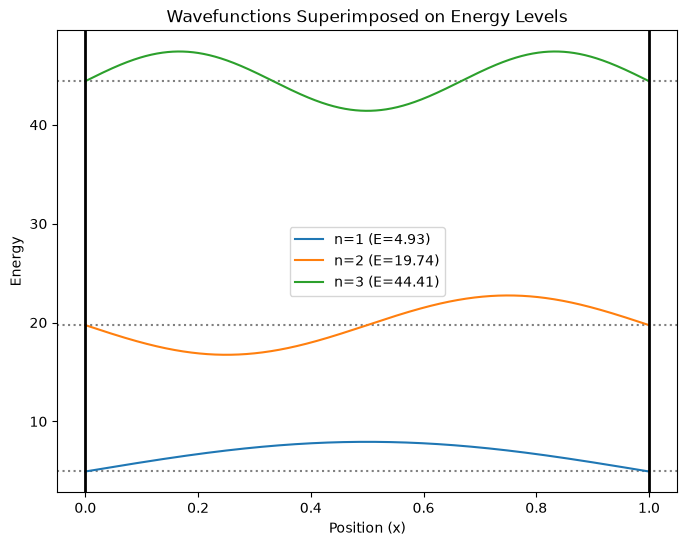

In [2]:
import numpy as np
import matplotlib.pyplot as plt

# taken hbar and m as 1
L = 1         # Width of the box
N = 1000         # Number of grid points
num_states = 3   # Number of states to plot

x = np.linspace(0, L, N)
dx = x[1] - x[0] # step function

 # forming hamiltonian matrix 

main_diag = np.ones(N-2) / (dx**2)
off_diag = -0.5 * np.ones(N-3) / (dx**2)

H = np.diag(main_diag) + np.diag(off_diag, -1) + np.diag(off_diag, 1)
energies, wavefunctions = np.linalg.eigh(H)


plt.figure(figsize=(8, 6))

for i in range(num_states):
    psi = np.zeros(N) # creates an array of all zeros matching entire spatial grid.
    psi[1:-1] = wavefunctions[:, i] #selects all elements of that array except the very first and very last slot
    #grabs the i-th solved numerical state from your matrix.
    psi = psi / np.max(np.abs(psi)) # psi /  absolute highest peak value of that specific wave state.
    
    E = energies[i]
    plt.axhline(E, color='gray', linestyle=':')
    plt.plot(x, (psi * 3) + E, label=f"n={i+1} (E={E:.2f})")


plt.axvline(0, color='black', linewidth=2)
plt.axvline(L, color='black', linewidth=2)
plt.title("Wavefunctions Superimposed on Energy Levels")
plt.xlabel("Position (x)")
plt.ylabel("Energy")
plt.legend()
plt.show()
